# Phase 1: a differentiable simulator, checked with a toy optimization

Before any neural network: can a loss on the drones' **final** positions be backpropagated through 100 physics steps to the accelerations that produced them? We optimize the acceleration sequence of one scene directly (a *fixed plan*). If 32 drones form a circle, the simulator, the Chamfer loss and autograd all work.

The math is in `docs/walkthrough/phase1.html`. All code is imported from `swarm/`; this notebook only runs it. About 1 minute end to end.

| Section | What it shows |
|---|---|
| 1 | Setup and config |
| 2 | Simulator: gradients reach every step, in the predicted ratios |
| 3 | Target shapes |
| 4 | Chamfer loss on a worked example |
| 5 | Toy optimization: 32 drones form a circle |
| 6 | Lesson: a constant learning rate diverges |
| 7 | Why a fixed plan is not enough (motivates Phase 2) |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import math
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from swarm import viz
from swarm.config import load_config
from swarm.losses import chamfer
from swarm.plan import optimize_plan
from swarm.shapes import sample_shape
from swarm.sim import rollout

cfg = load_config("configs/default.yaml")
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
N, T = cfg.n_agents, cfg.steps
lam = 1 - cfg.damping * cfg.dt
print(f"N = {N} drones, T = {T} steps of dt = {cfg.dt} s, damping c = {cfg.damping} (lambda = {lam}), a_max = {cfg.a_max}")

N = 32 drones, T = 100 steps of dt = 0.05 s, damping c = 0.5 (lambda = 0.975), a_max = 2.0


## 2. The simulator: gradients reach every step

One step: $v \leftarrow \lambda v + \Delta t\,a$, then $p \leftarrow p + \Delta t\,v$. Unrolled, the final position is a weighted sum of all accelerations, $p_T = p_0 + \sum_s w_s a_s$ with $w_s = \frac{\Delta t}{c}(1 - \lambda^{T-s})$. So the gradient of any loss on $p_T$ with respect to $a_s$ is proportional to $w_s$: early actions matter more, and damping caps the ratio.

In [2]:
torch.manual_seed(cfg.seed)
pos0 = torch.rand(1, N, 2) - 0.5
raw = torch.zeros(1, T, N, 2, requires_grad=True)
traj = rollout(pos0, torch.zeros_like(pos0), cfg.a_max * torch.tanh(raw), cfg)
traj[:, -1].pow(2).sum().backward()
g = raw.grad[0].norm(dim=(1, 2))
w = lambda s: cfg.dt / cfg.damping * (1 - lam ** (T - s))
print(f"{'step':>5s}{'measured |grad|':>18s}{'w_s (grad is proportional)':>28s}")
for s in (0, 50, 99):
    print(f"{s:5d}{g[s].item():18.4f}{w(s):28.4f}")
print(f"ratio first/last: measured {g[0] / g[99]:.1f}, predicted {w(0) / w(99):.1f}")

 step   measured |grad|  w_s (grad is proportional)
    0            0.8380                      0.0920
   50            0.6536                      0.0718
   99            0.0228                      0.0025
ratio first/last: measured 36.8, predicted 36.8


## 3. Target shapes

A shape is just a set of points, centered and scaled to fit the box. Phase 2's richer families (letters, words, hearts, spirals) live in `swarm/dataset.py`.

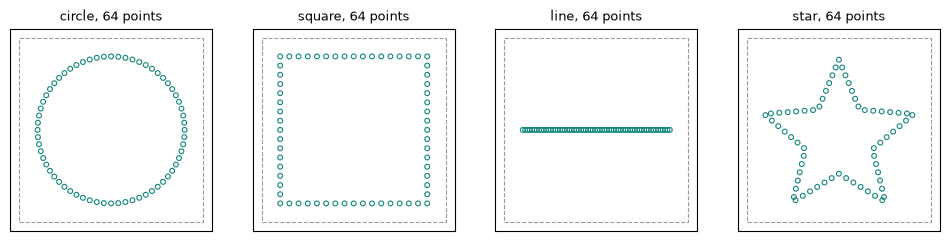

In [3]:
names = ["circle", "square", "line", "star"]
fig, axs = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, name in zip(axs, names):
    q = sample_shape(name, 64)
    viz._setup(ax, q, f"{name}, 64 points")
plt.show()

## 4. The Chamfer loss

$L = \frac1N\sum_i \min_j \lVert p_i - q_j\rVert^2 + \frac1M\sum_j \min_i \lVert p_i - q_j\rVert^2$: every drone near *some* goal, and every goal near *some* drone. No drone is assigned a spot. Worked example: two drones near one point of a 4-point circle.

In [4]:
Q4 = torch.tensor([[0.4, 0.0], [0.0, 0.4], [-0.4, 0.0], [0.0, -0.4]])
P2 = torch.tensor([[[0.4, 0.1], [0.3, 0.0]]])
D = ((P2[0, :, None] - Q4[None]) ** 2).sum(-1)
print("squared distances (rows: drones, columns: goals):\n", D.numpy().round(2))
print(f"A (drones -> shape) = {D.min(1).values.mean():.2f}   B (shape -> drones) = {D.min(0).values.mean():.2f}   "
      f"L = {chamfer(P2, Q4):.2f}")
print("All drones on one point:", round(chamfer(Q4[:1].repeat(5, 1)[None], Q4).item(), 3), "(A = 0, but B is large)")

squared distances (rows: drones, columns: goals):
 [[0.01 0.25 0.65 0.41]
 [0.01 0.25 0.49 0.25]]
A (drones -> shape) = 0.01   B (shape -> drones) = 0.25   L = 0.26
All drones on one point: 0.32 (A = 0, but B is large)


## 5. Toy optimization: 32 drones form a circle

300 Adam iterations on the 6,400 raw numbers (a = a_max·tanh(raw)), cosine learning-rate decay. The best possible loss for 32 drones on 64 circle points is $\tfrac38 s^2$ (each drone a quarter of the way between two goals).

iter    0   loss 0.032678
iter   50   loss 0.001998


iter  100   loss 0.000722
iter  150   loss 0.000650


iter  200   loss 0.000650
iter  250   loss 0.000650


iter  299   loss 0.000650

final loss 0.000650   best possible 0.000578


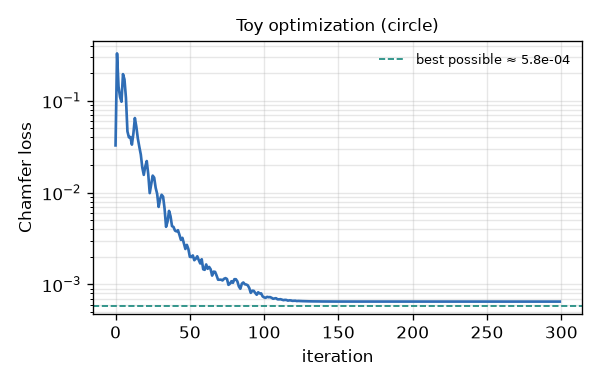

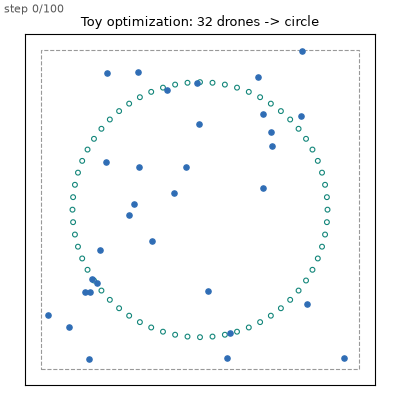

In [5]:
Q = sample_shape("circle", 2 * N)[None]
out = optimize_plan(pos0, Q, cfg, iters=300, lr=0.05, log_every=50)
spacing = 2 * 0.4 * math.sin(math.pi / (2 * N))
floor = 3 / 8 * spacing ** 2
print(f"\nfinal loss {out['history'][-1]:.6f}   best possible {floor:.6f}")
viz.plot_loss(out["history"], FIGS / "phase1_loss.png", title="Toy optimization (circle)", floor=floor)
gif = viz.save_gif(out["traj"][0], Q[0], GIFS / "phase1_circle.gif", title=f"Toy optimization: {N} drones -> circle")
display(Image(filename=FIGS / "phase1_loss.png"), Image(filename=gif))

## 6. Lesson: a constant learning rate diverges

Adam moves every parameter by about the learning rate however small its gradient is. One aligned step can move a final position by up to $a_{\max}\,\eta\sum_s w_s \approx 0.64$, far more than the 0.04 spacing of the goals, so near the optimum the drones keep overshooting.

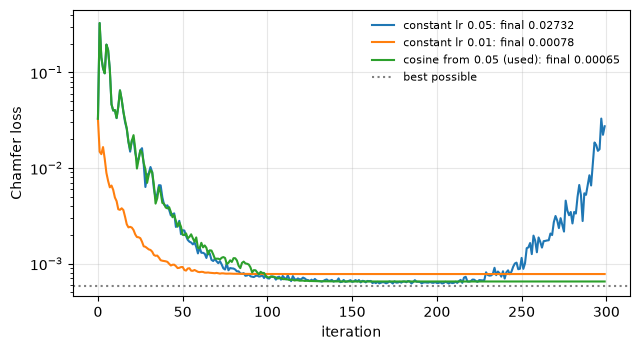

In [6]:
runs = {"constant lr 0.05": dict(lr=0.05, cosine=False), "constant lr 0.01": dict(lr=0.01, cosine=False),
        "cosine from 0.05 (used)": dict(lr=0.05, cosine=True)}
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, kw in runs.items():
    h = optimize_plan(pos0, Q, cfg, iters=300, **kw)["history"]
    ax.semilogy(h, label=f"{name}: final {h[-1]:.5f}")
ax.axhline(floor, color="0.5", ls=":", label="best possible")
ax.set_xlabel("iteration"); ax.set_ylabel("Chamfer loss"); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "phase1_lr.png"); plt.show()

## 7. Why a fixed plan is not enough

The plan above is 6,400 numbers tuned for one start. Replayed from other starts, toward another shape, or with drones missing, it fails: it never looks at where the drones are, and it was computed centrally. Phase 2 replaces it with one shared policy that each drone runs on what it sees.

In [7]:
acc = out["accs"]
v0 = torch.zeros(1, N, 2)
g1 = torch.Generator().manual_seed(1)
starts = torch.rand(15, N, 2, generator=g1) - 0.5
keep = torch.arange(N) >= 8
with torch.no_grad():
    rows = {
        "start it was optimized for": chamfer(rollout(pos0, v0, acc, cfg)[:, -1], Q).item(),
        "15 new starts (mean)": chamfer(rollout(starts, v0.expand(15, -1, -1), acc.expand(15, -1, -1, -1), cfg)[:, -1], Q).item(),
        "target is a square instead": chamfer(rollout(pos0, v0, acc, cfg)[:, -1], sample_shape("square", 2 * N)[None]).item(),
        "8 of 32 drones removed": chamfer(rollout(pos0[:, keep], v0[:, keep], acc[:, :, keep], cfg)[:, -1], Q).item(),
        "drones left where they started": chamfer(pos0, Q).item(),
    }
for k, v in rows.items():
    print(f"{k:32s} {v:.5f}")

start it was optimized for       0.00065
15 new starts (mean)             0.16183
target is a square instead       0.00987
8 of 32 drones removed           0.00158
drones left where they started   0.03268
